# Exploration Q7 & Q8 : Typologie des stations et politique de rééquilibrage

Ce notebook présente l'exploration des données nettoyées de CityCycle afin d'identifier des profils de stations et d'en déduire une politique de rééquilibrage adaptée.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

# import des modules depuis /src
sys.path.append(str(Path("../src").resolve()))

from data_loader import get_prepared_dataset
from features import flux_station_heure, profil_stations

## 1. Chargement et exploration rapide des variables

In [2]:
df_stations, df_trajets, _ = get_prepared_dataset()
flux = flux_station_heure(df_trajets, df_stations)
df_profil = profil_stations(flux, df_stations)

cols = ["capacite", "altitude_m", "interventions_mois"]
display(df_stations[cols].describe().round(1))

,capacite,altitude_m,interventions_mois
count,140.0,140.0,140.0
mean,21.9,54.6,5.1
std,7.1,21.5,3.5
min,8.0,25.0,0.0
25%,17.0,37.0,3.0
50%,21.0,51.0,4.0
75%,27.0,70.0,6.0
max,44.0,109.0,20.0


## 2. Choix du nombre de clusters $k$ (Inertie et Silhouette)

,k,inertie,silhouette
0,2,304.4,0.29
1,3,223.5,0.31
2,4,172.1,0.30
3,5,144.0,0.29


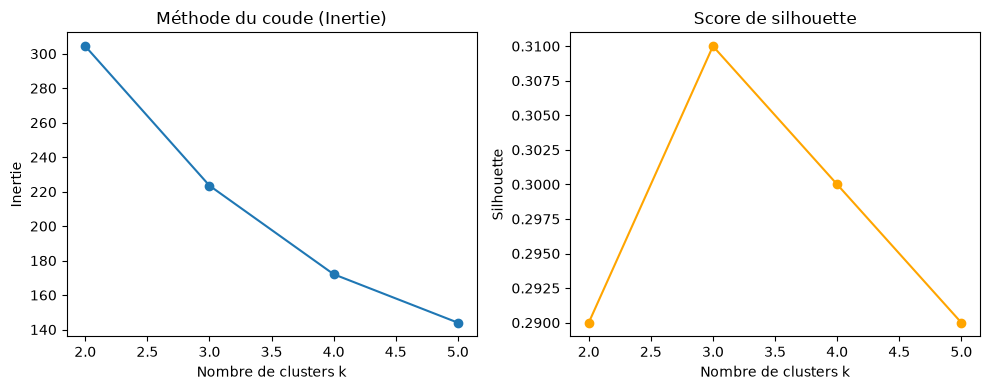

In [3]:
X = StandardScaler().fit_transform(df_stations[cols])

resultats_k = []

for k in range(2, 6):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X)
    resultats_k.append({
        "k": k,
        "inertie": round(km.inertia_, 1),
        "silhouette": round(silhouette_score(X, labels), 2),
    })

df_k = pd.DataFrame(resultats_k)
display(df_k)

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(df_k["k"], df_k["inertie"], marker="o")
ax[0].set_title("Méthode du coude (Inertie)")
ax[0].set_xlabel("Nombre de clusters k")
ax[0].set_ylabel("Inertie")

ax[1].plot(df_k["k"], df_k["silhouette"], marker="o", color="orange")
ax[1].set_title("Score de silhouette")
ax[1].set_xlabel("Nombre de clusters k")
ax[1].set_ylabel("Silhouette")
plt.tight_layout()
plt.show()

**Choix retenu : $k = 3$**
- Pour $k = 3$, les stations sont bien regroupées autour du centre (baisse nette de l'inertie) et le score de silhouette atteint son maximum ($0{,}31$) parmi les valeurs testées.
- Sur le plan métier, 3 profils distinguent clairement les stations calmes, les grandes stations régulières et le groupe critique des gares.

## 3. Profil des 3 clusters et croisement avec les quartiers (Question 7)

,nb_stations,capacite_moy,altitude_moy,interventions_moy,dep_matin_moy,arr_matin_moy,taux_vidage_moy
cluster,,,,,,,
0,54,17.9,70.8,3.7,1.4,1.3,0.5
1,71,25.9,40.9,4.5,1.3,1.5,0.5
2,15,17.1,61.5,12.9,1.5,0.7,0.5


type_quartier,bureaux,gare,résidentiel,université
cluster,,,,
0,24,1,13,16
1,26,7,25,13
2,1,13,1,0


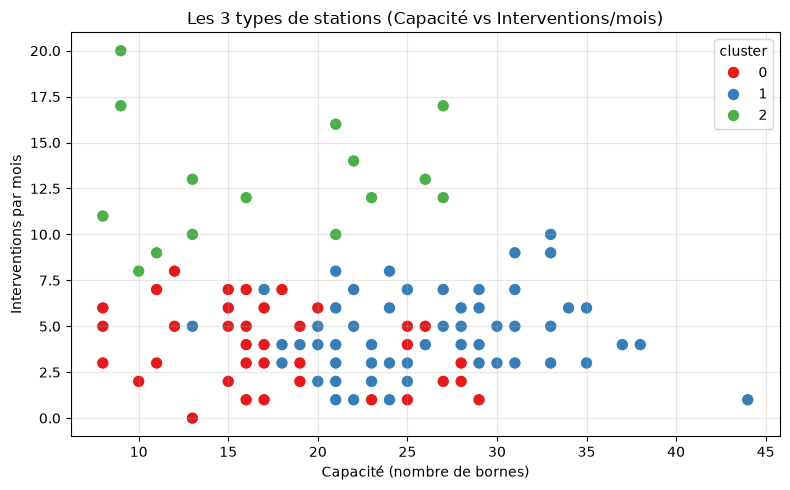

In [4]:
df_stations["cluster"] = KMeans(n_clusters=3, n_init=10, random_state=42).fit_predict(X)
df_profil["cluster"] = df_stations["cluster"].values

resume = df_profil.groupby("cluster").agg(
    nb_stations=("station", "count"),
    capacite_moy=("capacite", "mean"),
    altitude_moy=("altitude_m", "mean"),
    interventions_moy=("interventions_mois", "mean"),
    dep_matin_moy=("dep_matin", "mean"),
    arr_matin_moy=("arr_matin", "mean"),
    taux_vidage_moy=("taux_vidage", "mean"),
).round(1)

display(resume)
display(pd.crosstab(df_stations["cluster"], df_stations["type_quartier"]))

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df_stations,
    x="capacite",
    y="interventions_mois",
    hue="cluster",
    palette="Set1",
    s=80,
)
plt.title("Les 3 types de stations (Capacité vs Interventions/mois)")
plt.xlabel("Capacité (nombre de bornes)")
plt.ylabel("Interventions par mois")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 4. Déduction de la politique de rééquilibrage (Question 8)

In [5]:
stations = df_stations.merge(
    df_profil[["station", "dep_matin", "arr_matin"]],
    left_on="station_id",
    right_on="station",
    how="left",
)
stations["departs_matin"] = stations["dep_matin"].fillna(0)
stations["arrivees_matin"] = stations["arr_matin"].fillna(0)
stations["solde_matin"] = stations["arrivees_matin"] - stations["departs_matin"]

resume_clusters = stations.groupby("cluster").agg(
    interventions_moy=("interventions_mois", "mean"),
    capacite_moy=("capacite", "mean"),
)
cluster_prioritaire = resume_clusters["interventions_moy"].idxmax()
cluster_regulation = resume_clusters.drop(index=cluster_prioritaire)["capacite_moy"].idxmax()

politiques = {
    c: (
        "Priorité haute dès 7h" if c == cluster_prioritaire
        else "Régulation standard en journée" if c == cluster_regulation
        else "Passage sur seuil (pas à 7h)"
    )
    for c in resume_clusters.index
}
stations["politique"] = stations["cluster"].map(politiques)

display(stations.groupby(["cluster", "politique"]).agg(
    nb_stations=("station_id", "count"),
    interventions_moy=("interventions_mois", "mean"),
    departs_matin=("departs_matin", "mean"),
    arrivees_matin=("arrivees_matin", "mean"),
    solde_matin=("solde_matin", "mean"),
).round(1))

,,nb_stations,interventions_moy,departs_matin,arrivees_matin,solde_matin
cluster,politique,,,,,
0,Passage sur seuil (pas à 7h),54,3.7,1.4,1.3,-0.1
1,Régulation standard en journée,71,4.5,1.3,1.5,0.2
2,Priorité haute dès 7h,15,12.9,1.5,0.7,-0.7
